# Does a better solution exist inside the combined parametrization?

GD trained in the `combined` parametrization reaches a worse cross-entropy than GD trained in
`separate` — 7/7 thresholds on test in `ICL-equiprobable-successors`. There are two possible
explanations:

1. **Expressivity.** `combined` cannot represent the function `separate` found.
2. **Optimization.** `combined` *can* represent it, but gradient descent does not get there.

This notebook settles which. For every one of the 7 trained `separate` runs we collapse the
learned factors,

$$W_{qk}=W_Q^\top W_K,\qquad W_{ov}=W_V^\top W_O^\top ,$$

load the result into a `combined` model, and re-measure the cross-entropy on the **full train and
test splits**.

If the collapsed model scores identically, then each `separate` solution has an exact twin
sitting inside `combined`'s parameter space — so a `combined` model at least that good provably
exists, and explanation 1 is dead.

### Why the collapse should be exact here

The layer-2 factors have shapes $W_Q,W_K\in\R^{108\times216}$, so $W_Q^\top W_K$ has rank at most
$108$, while `combined` stores an unconstrained $216\times216$ matrix. The product therefore
always fits. (The reverse direction does **not** hold in general — a learned combined $W_{qk}$ of
rank $>108$ has no exact separate factorization.)

Unlike the hand construction, these matrices are **dense**, so float32 summation order does
matter and small numerical differences are expected rather than bitwise equality.

## 1. Setup

In [1]:
import glob, importlib.util, json, os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

F14 = os.path.join('..', '14. elimination final convergence confusion')
_s = importlib.util.spec_from_file_location('tw', os.path.join(F14, 'train_with_equiprobable.py'))
TW = importlib.util.module_from_spec(_s); _s.loader.exec_module(TW)
Model = TW.SimplifiedTransformerMLP

CELL = 'equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000'
CDIR = os.path.join(F14, 'runs', CELL)
DATA = os.path.join(F14, 'dataset')
CACHE = os.path.join(F14, 'artifacts', CELL, 'curves.json')
ART = 'artifacts'; os.makedirs(ART, exist_ok=True)

V, VS, T = 8, 4, 100
D, IN2 = V + T, 2 * (V + T)
K_LOG, EPS = TW.CFG['freeze_hidden_k'], TW.CFG['freeze_delta']
TS, TE = TW.CFG['token_start'], T
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SPLITS = ['train', 'test']
THRS = sorted(float(p.split('_x_')[1][:-4])
              for p in glob.glob(os.path.join(CDIR, 'model_separate_*.pth')))

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 170, 'font.size': 13,
                     'axes.titlesize': 14, 'axes.labelsize': 13, 'xtick.labelsize': 12,
                     'ytick.labelsize': 12, 'legend.fontsize': 11, 'figure.titlesize': 15,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 2.0,
                     'legend.frameon': False})

print(f'cell   : {CELL}')
print(f'device : {DEV}')
print(f'thresholds ({len(THRS)}): {THRS}')


cell   : equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000
device : cuda
thresholds (7): [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


## 2. Collapse a trained separate model into combined

Only the four attention circuits change. `ff1`, `ff2` and `fc_out` are copied verbatim, so the
two models differ in exactly one respect.

In [2]:
def load_separate(thr):
    m = Model(V, T, D, VS, K_LOG, True, 'separate').to(DEV)
    m.load_state_dict(torch.load(os.path.join(CDIR, f'model_separate_seed0_x_{thr}.pth'),
                                 map_location=DEV, weights_only=True))
    return m.eval()

def collapse(msep):
    m = Model(V, T, D, VS, K_LOG, True, 'combined').to(DEV)
    with torch.no_grad():
        for src, dst in ((msep.layer1, m.layer1), (msep.layer2, m.layer2)):
            dst.W_qk.copy_(src.W_q.weight.t() @ src.W_k.weight)
            dst.W_ov.copy_(src.W_v.weight.t() @ src.W_o.weight.t())
        for name in ('ff1', 'ff2', 'fc_out'):
            getattr(m, name).weight.copy_(getattr(msep, name).weight)
            getattr(m, name).bias.copy_(getattr(msep, name).bias)
    return m.eval()

@torch.no_grad()
def ce(m, split, thr, batch=256):
    b = torch.load(os.path.join(DATA, split, f'data_x_{thr}.pt'), weights_only=False)
    x, y = b['x'], b['y']
    tot = n = 0.0
    for i in range(0, x.shape[0], batch):
        xb = x[i:i + batch].to(DEV)
        yb = y[i:i + batch, TS:TE].to(DEV)
        lg = m(xb)[:, TS:TE]
        tot += F.cross_entropy(lg.reshape(-1, V), yb.reshape(-1), reduction='sum').item()
        n += yb.numel()
    return tot / n

_m = load_separate(THRS[0])
_c = collapse(_m)
print(f'separate  {sum(p.numel() for p in _m.parameters()):,} params  '
      f'-> combined  {sum(p.numel() for p in _c.parameters()):,} params')
print(f'ff1/ff2/fc_out carried over unchanged: '
      f'{all(torch.equal(getattr(_m,n).weight, getattr(_c,n).weight) for n in ("ff1","ff2","fc_out"))}')
for i, (a, b_) in enumerate([(_m.layer1, _c.layer1), (_m.layer2, _c.layer2)], 1):
    r = torch.linalg.matrix_rank(b_.W_qk.float()).item()
    print(f'  layer{i}  W_qk {tuple(b_.W_qk.shape)}  rank {r} / {min(b_.W_qk.shape)}   '
          f'W_ov {tuple(b_.W_ov.shape)}')
del _m, _c

/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


separate  463,516 params  -> combined  428,524 params
ff1/ff2/fc_out carried over unchanged: True


  layer1  W_qk (108, 108)  rank 105 / 108   W_ov (108, 108)
  layer2  W_qk (216, 216)  rank 108 / 216   W_ov (216, 108)


## 3. Does the cross-entropy survive the collapse?

Full splits: 25 000 train and 10 000 test sequences per threshold.

In [3]:
rows = []
print(f'{"alpha":>6s} {"split":>6s} {"separate":>12s} {"collapsed":>12s} {"diff":>11s} {"rel":>10s}')
for thr in THRS:
    ms = load_separate(thr)
    mc = collapse(ms)
    r = {'threshold': thr}
    for sp in SPLITS:
        a, b_ = ce(ms, sp, thr), ce(mc, sp, thr)
        r[f'sep_{sp}'], r[f'col_{sp}'] = a, b_
        print(f'{thr:6.1f} {sp:>6s} {a:12.6f} {b_:12.6f} {a - b_:11.2e} {abs(a-b_)/a:10.2e}')
    rows.append(r)
    del ms, mc

worst = max(abs(r[f'sep_{sp}'] - r[f'col_{sp}']) for r in rows for sp in SPLITS)
print(f'\nworst absolute CE change over all 7 runs x 2 splits: {worst:.3e} nats')

 alpha  split     separate    collapsed        diff        rel


   0.4  train     1.800249     1.800249   -5.16e-08   2.86e-08


   0.4   test     1.815820     1.815820   -1.86e-08   1.02e-08


   0.5  train     1.742381     1.742382   -6.25e-08   3.59e-08


   0.5   test     1.770658     1.770658   -8.40e-08   4.74e-08


   0.6  train     1.649636     1.649636    4.06e-08   2.46e-08


... (5 outputs left out)

   0.9  train     1.090342     1.090342   -1.94e-07   1.78e-07


   0.9   test     1.109777     1.109778   -2.54e-07   2.29e-07


   1.0  train     0.692992     0.692992   -1.01e-07   1.45e-07


   1.0   test     0.708733     0.708733    2.21e-07   3.12e-07

worst absolute CE change over all 7 runs x 2 splits: 4.983e-07 nats


## 4. Reference curves

`ideal-`$\alpha$, the in-architecture hand construction, and GD-combined are read from the cache
written by `14/analyse_equiprobable.ipynb` — identical data, identical settings. The separate
numbers recomputed above are cross-checked against that cache.

In [4]:
cache = json.load(open(CACHE))
REF = {sp: {k: [cache[f'{sp}|{t}|eps{EPS}'][k] for t in THRS]
            for k in ('ideal', 'construction', 'combined', 'separate')} for sp in SPLITS}

drift = max(abs(REF[sp]['separate'][i] - rows[i][f'sep_{sp}'])
            for sp in SPLITS for i in range(len(THRS)))
print(f'recomputed separate CE vs cached: max|diff| = {drift:.2e}')

CURVES = {sp: {'ideal': REF[sp]['ideal'],
               'construction': REF[sp]['construction'],
               'combined': REF[sp]['combined'],
               'separate': [r[f'sep_{sp}'] for r in rows],
               'collapsed': [r[f'col_{sp}'] for r in rows]} for sp in SPLITS}

recomputed separate CE vs cached: max|diff| = 0.00e+00


## 5. Cross-entropy vs $\alpha$

`separate` is drawn as a solid line and `separate collapsed into combined` as open markers on top
of it: if the collapse is faithful the markers sit exactly on the line. GD-combined is the curve
that matters for the conclusion — it is what gradient descent actually reaches in that
parametrization.

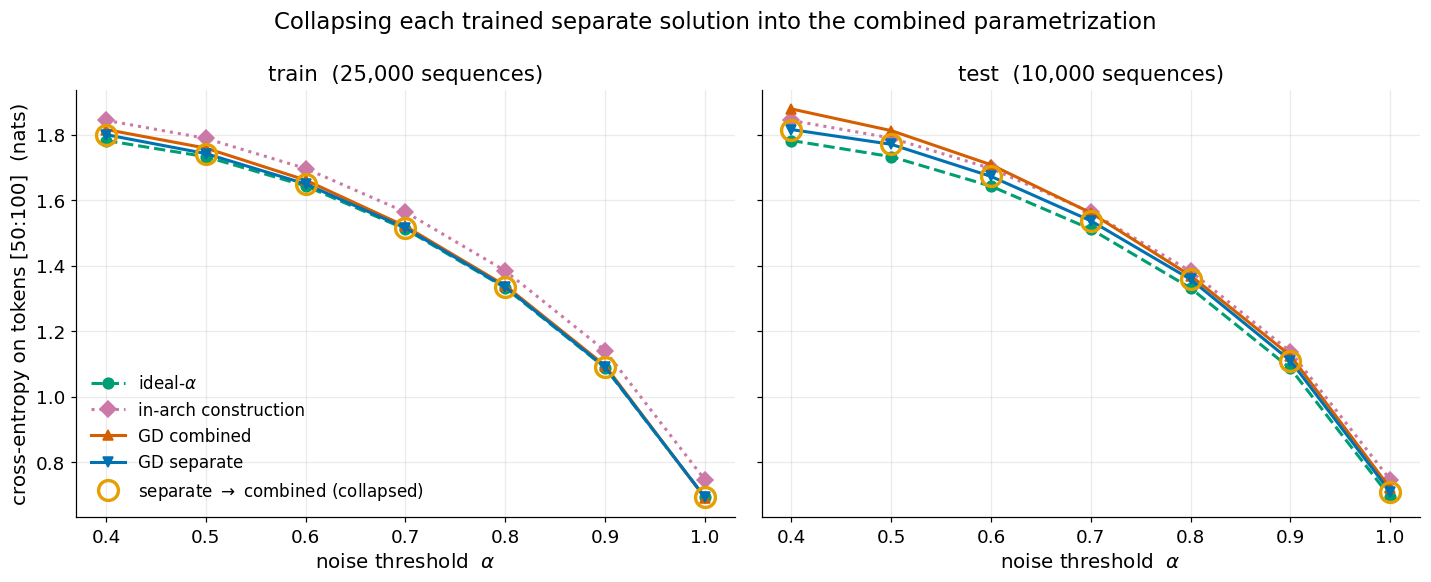

In [5]:
SERIES = [
    ('ideal',        dict(color='#009E73', marker='o', ls='--', lw=2.0, ms=7,
                          label=r'ideal-$\alpha$')),
    ('construction', dict(color='#CC79A7', marker='D', ls=':',  lw=2.0, ms=7,
                          label='in-arch construction')),
    ('combined',     dict(color='#D55E00', marker='^', ls='-',  lw=2.0, ms=7,
                          label='GD combined')),
    ('separate',     dict(color='#0072B2', marker='v', ls='-',  lw=2.0, ms=7,
                          label='GD separate')),
    ('collapsed',    dict(color='#E69F00', marker='o', ls='none', ms=13,
                          mfc='none', mew=2.2,
                          label=r'separate $\to$ combined (collapsed)')),
]

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4), sharey=True)
for ax, sp in zip(axes, SPLITS):
    for key, st in SERIES:
        ax.plot(THRS, CURVES[sp][key], **st)
    n = torch.load(os.path.join(DATA, sp, f'data_x_{THRS[0]}.pt'),
                   weights_only=False)['x'].shape[0]
    ax.set_title(f'{sp}  ({n:,} sequences)')
    ax.set_xlabel(r'noise threshold  $\alpha$'); ax.set_xticks(THRS)
axes[0].set_ylabel(f'cross-entropy on tokens [{TS}:{TE}]  (nats)')
axes[0].legend(loc='lower left')
fig.suptitle('Collapsing each trained separate solution into the combined parametrization')
fig.tight_layout()
fig.savefig(os.path.join(ART, 'separate_to_combined_ce.png'), bbox_inches='tight')
plt.show()

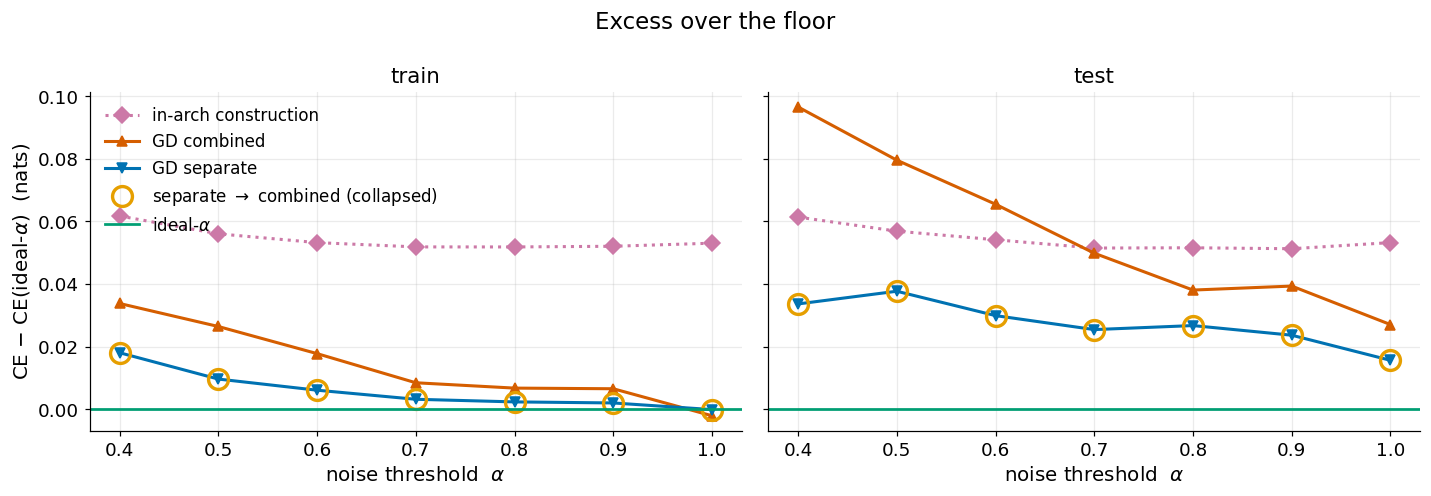

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6), sharey=True)
for ax, sp in zip(axes, SPLITS):
    base = np.array(CURVES[sp]['ideal'])
    for key, st in SERIES[1:]:
        ax.plot(THRS, np.array(CURVES[sp][key]) - base, **st)
    ax.axhline(0, color='#009E73', lw=1.8, label=r'ideal-$\alpha$')
    ax.set_title(sp); ax.set_xlabel(r'noise threshold  $\alpha$'); ax.set_xticks(THRS)
axes[0].set_ylabel(r'CE $-$ CE(ideal-$\alpha$)  (nats)')
axes[0].legend(loc='upper left')
fig.suptitle('Excess over the floor')
fig.tight_layout()
fig.savefig(os.path.join(ART, 'separate_to_combined_excess.png'), bbox_inches='tight')
plt.show()

## 6. Exact values

In [7]:
import csv
ORDER = ['ideal', 'construction', 'combined', 'separate', 'collapsed']
LBL = {'ideal': 'ideal', 'construction': 'construction', 'combined': 'GD combined',
       'separate': 'GD separate', 'collapsed': 'collapsed'}
hdr = f'{"thr":>5s} | ' + ' | '.join(f'{LBL[k]:>21s}' for k in ORDER)
print(hdr); print(f'{"":>5s} | ' + ' | '.join(f'{"train":>10s} {"test":>10s}' for _ in ORDER))
print('-' * len(hdr))
out = []
for i, t in enumerate(THRS):
    r = {'threshold': t}
    for k in ORDER:
        r[f'{k}_train'] = round(CURVES['train'][k][i], 6)
        r[f'{k}_test'] = round(CURVES['test'][k][i], 6)
    out.append(r)
    print(f'{t:5.1f} | ' + ' | '.join(
        f'{CURVES["train"][k][i]:10.4f} {CURVES["test"][k][i]:10.4f}' for k in ORDER))
p = os.path.join(ART, 'separate_to_combined_ce.csv')
with open(p, 'w', newline='') as fh:
    w = csv.DictWriter(fh, fieldnames=list(out[0])); w.writeheader(); w.writerows(out)
print(f'\nwrote {p}')

  thr |                 ideal |          construction |           GD combined |           GD separate |             collapsed
      |      train       test |      train       test |      train       test |      train       test |      train       test
-----------------------------------------------------------------------------------------------------------------------------
  0.4 |     1.7822     1.7822 |     1.8439     1.8436 |     1.8160     1.8788 |     1.8002     1.8158 |     1.8002     1.8158
  0.5 |     1.7328     1.7330 |     1.7888     1.7899 |     1.7592     1.8125 |     1.7424     1.7707 |     1.7424     1.7707
  0.6 |     1.6436     1.6428 |     1.6968     1.6969 |     1.6613     1.7083 |     1.6496     1.6727 |     1.6496     1.6727
  0.7 |     1.5118     1.5117 |     1.5636     1.5631 |     1.5202     1.5615 |     1.5150     1.5371 |     1.5150     1.5371
  0.8 |     1.3324     1.3315 |     1.3842     1.3830 |     1.3391     1.3695 |     1.3347     1.3582 |     1.3347    

## 7. Verdict

In [8]:
gap = {sp: np.array(CURVES[sp]['combined']) - np.array(CURVES[sp]['collapsed'])
       for sp in SPLITS}
print(f'collapse changes CE by at most {worst:.2e} nats -> the collapsed model IS the '
      f'separate solution\n')
print('GD combined  minus  collapsed separate  (how much GD leaves on the table in the '
      'combined coordinates):')
for sp in SPLITS:
    d = gap[sp]
    print(f'  {sp:5s} ' + '  '.join(f'{t}:{v:+.4f}' for t, v in zip(THRS, d)) +
          f'   | mean {d.mean():+.4f}   worse at {int((d > 0).sum())}/{len(d)} thresholds')
print()
if worst < 1e-4 and gap['test'].mean() > 0:
    print('CONCLUSION')
    print('  For every threshold there exists a point in COMBINED parameter space that scores')
    print('  exactly what GD-separate scores -- it is the collapse of the separate solution.')
    print('  GD in the combined parametrization does not find it, and settles higher instead.')
    print('  The deficit is therefore OPTIMIZATION, not expressivity: the better solution is')
    print('  reachable in principle and simply is not reached.')
    print()
    print('  Caveat: this shows a better point exists, not that it is a minimum GD could have')
    print('  converged to from a random init. It rules out the expressivity explanation only.')
else:
    print('Unexpected result -- inspect the numbers above before drawing any conclusion.')

collapse changes CE by at most 4.98e-07 nats -> the collapsed model IS the separate solution

GD combined  minus  collapsed separate  (how much GD leaves on the table in the combined coordinates):
  train 0.4:+0.0157  0.5:+0.0168  0.6:+0.0117  0.7:+0.0053  0.8:+0.0044  0.9:+0.0045  1.0:-0.0020   | mean +0.0081   worse at 6/7 thresholds
  test  0.4:+0.0629  0.5:+0.0419  0.6:+0.0356  0.7:+0.0244  0.8:+0.0113  0.9:+0.0157  1.0:+0.0114   | mean +0.0290   worse at 7/7 thresholds

CONCLUSION
  For every threshold there exists a point in COMBINED parameter space that scores
  exactly what GD-separate scores -- it is the collapse of the separate solution.
  GD in the combined parametrization does not find it, and settles higher instead.
  The deficit is therefore OPTIMIZATION, not expressivity: the better solution is
  reachable in principle and simply is not reached.

  Caveat: this shows a better point exists, not that it is a minimum GD could have
  converged to from a random init. It rules

---

# 8. Are these solutions actually at a local minimum?

Section 7 showed a better point exists in combined's parameter space. That leaves the question of
what kind of point each solution actually is. Three configurations are measured:

| configuration | parameters differentiated |
|---|---|
| separate @ separate's solution | $W_Q,W_K,W_V,W_O$ (both layers) $+\ W_u$ |
| combined @ combined's solution | $W_{qk},W_{ov}$ (both layers) $+\ W_u$ |
| combined @ **collapsed** separate solution | $W_{qk},W_{ov}$ (both layers) $+\ W_u$ |

`ff1`/`ff2` are frozen in every run and are excluded, exactly as during training.

### What the gradient can and cannot tell us

The gradient is taken over the **full split**, not a minibatch, so it is the true gradient of the
objective the runs were optimising.

Two cautions:

**Magnitudes are not comparable across parametrizations.** separate has 130 904 trainable
parameters and combined 95 912, and the collapse is not an isometry — the same function sits at
different points in two different geometries. A raw $\|\nabla\|$ comparison between the first row
and the other two is meaningless. Within the combined rows it *is* meaningful, because those two
share coordinates.

**A small gradient is necessary, not sufficient.** The decisive quantity is the chain rule through
the collapse. With $L(W_Q,W_K)=\tilde L(W_Q^\top W_K)$,

$$\nabla_{W_Q}L = W_K\bigl(\nabla_{W_{qk}}\tilde L\bigr)^\top,
\qquad \nabla_{W_K}L = W_Q\,\nabla_{W_{qk}}\tilde L .$$

So $\nabla_{W_{qk}}\tilde L=0 \Rightarrow$ both separate gradients vanish, but **not** the
converse: if $W_Q,W_K$ are rank-deficient, the separate gradient can vanish while the combined
gradient does not. Layer-2 $W_{qk}$ here has rank 108 out of 216, so that null space is large and
this is a live possibility. Section 10 tests it directly by trying to descend.

In [9]:
def full_grad(m, split, thr, batch=256):
    b = torch.load(os.path.join(DATA, split, f'data_x_{thr}.pt'), weights_only=False)
    x, y = b['x'], b['y']
    n_tok = x.shape[0] * (TE - TS)
    for p in m.parameters():
        p.requires_grad_(False)
    params = TW.trainable(m)
    for p in params:
        p.requires_grad_(True); p.grad = None
    tot = 0.0
    for i in range(0, x.shape[0], batch):
        xb = x[i:i + batch].to(DEV)
        yb = y[i:i + batch, TS:TE].to(DEV)
        loss = F.cross_entropy(m(xb)[:, TS:TE].reshape(-1, V), yb.reshape(-1),
                               reduction='sum') / n_tok
        loss.backward()
        tot += loss.item()
    grads = [p.grad.detach().clone() for p in params]
    g = torch.cat([gi.reshape(-1) for gi in grads])
    th = torch.cat([p.detach().reshape(-1) for p in params])
    for p in params:
        p.grad = None
    return dict(loss=tot, grads=grads, gnorm=float(g.norm()), n=g.numel(),
                rms=float(g.norm()) / g.numel() ** 0.5,
                rel=float(g.norm()) / float(th.norm()), gmax=float(g.abs().max()))

def load_combined(thr):
    m = Model(V, T, D, VS, K_LOG, True, 'combined').to(DEV)
    m.load_state_dict(torch.load(os.path.join(CDIR, f'model_combined_seed0_x_{thr}.pth'),
                                 map_location=DEV, weights_only=True))
    return m.eval()

CONFIGS = [('separate @ separate', lambda t: load_separate(t)),
           ('combined @ combined', lambda t: load_combined(t)),
           ('combined @ collapsed', lambda t: collapse(load_separate(t)))]

G = {name: {sp: [] for sp in SPLITS} for name, _ in CONFIGS}
print(f'{"configuration":22s} {"alpha":>5s} {"split":>6s} {"loss":>9s} {"||grad||":>11s} '
      f'{"RMS":>10s} {"||g||/||w||":>12s} {"max|g|":>10s}')
for name, mk in CONFIGS:
    for thr in THRS:
        m = mk(thr)
        for sp in SPLITS:
            r = full_grad(m, sp, thr)
            G[name][sp].append(r)
            print(f'{name:22s} {thr:5.1f} {sp:>6s} {r["loss"]:9.4f} {r["gnorm"]:11.3e} '
                  f'{r["rms"]:10.3e} {r["rel"]:12.3e} {r["gmax"]:10.3e}')
        del m
print(f'\ntrainable parameter counts: '
      f'{ {n: G[n]["train"][0]["n"] for n, _ in CONFIGS} }')

configuration          alpha  split      loss    ||grad||        RMS  ||g||/||w||     max|g|


separate @ separate      0.4  train    1.8002   3.403e-01  9.407e-04    8.905e-04  1.593e-01


separate @ separate      0.4   test    1.8158   3.705e-01  1.024e-03    9.693e-04  1.844e-01


separate @ separate      0.5  train    1.7424   7.448e-02  2.058e-04    2.099e-04  2.536e-02


separate @ separate      0.5   test    1.7707   7.983e-02  2.206e-04    2.250e-04  2.556e-02


separate @ separate      0.6  train    1.6496   1.233e-01  3.408e-04    3.817e-04  5.138e-02


... (33 outputs left out)

combined @ collapsed     0.9  train    1.0903   9.123e-02  2.946e-04    1.884e-05  4.651e-02


combined @ collapsed     0.9   test    1.1098   8.437e-02  2.724e-04    1.742e-05  3.617e-02


combined @ collapsed     1.0  train    0.6930   1.827e-01  5.899e-04    8.837e-05  7.841e-02


combined @ collapsed     1.0   test    0.7087   1.947e-01  6.285e-04    9.416e-05  8.252e-02

trainable parameter counts: {'separate @ separate': 130904, 'combined @ combined': 95912, 'combined @ collapsed': 95912}


## 9. Gradient magnitude vs $\alpha$

Log scale. Compare the two **combined** curves against each other; the separate curve lives in a
different coordinate system and is shown for reference only.

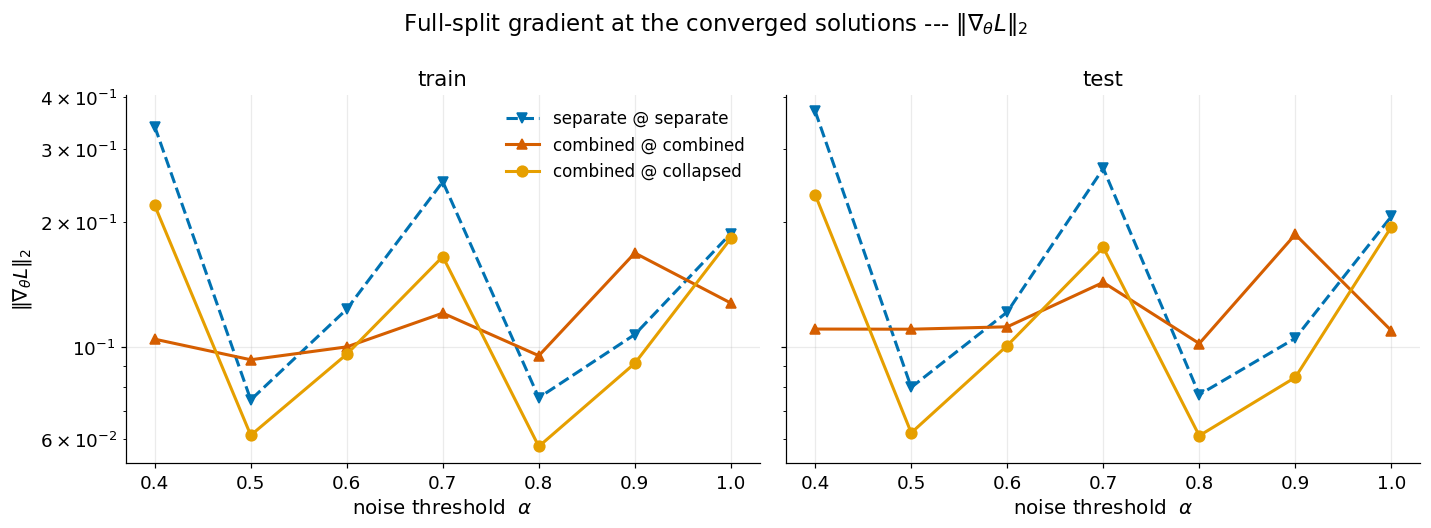

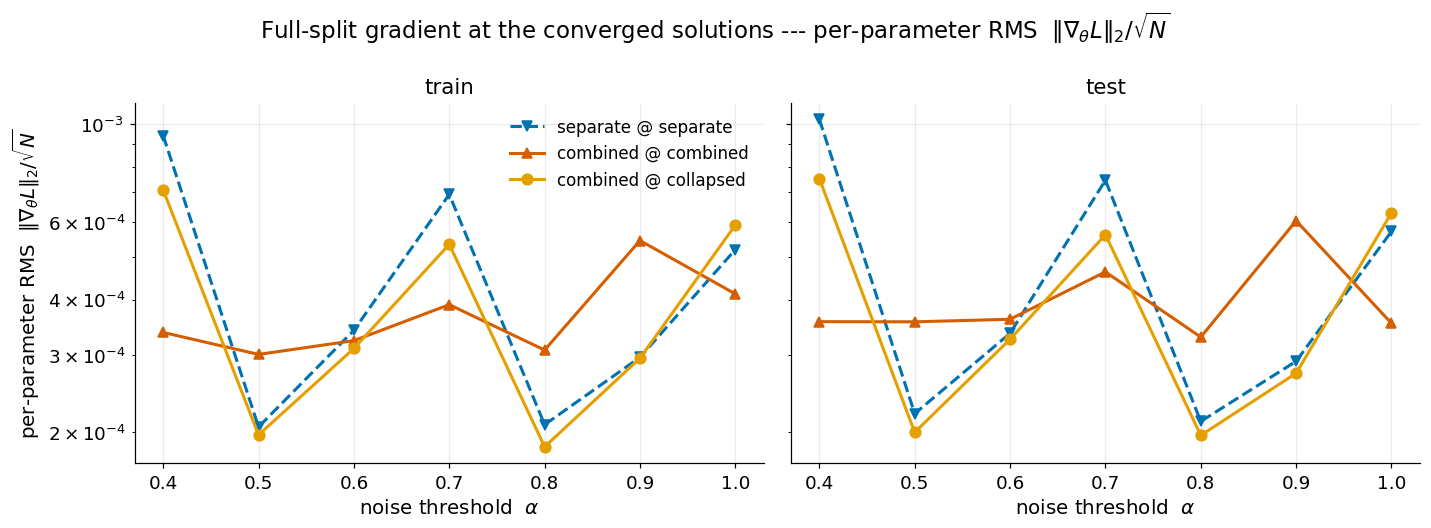

In [10]:
GST = [('separate @ separate',  dict(color='#0072B2', marker='v', ls='--')),
       ('combined @ combined',  dict(color='#D55E00', marker='^', ls='-')),
       ('combined @ collapsed', dict(color='#E69F00', marker='o', ls='-'))]

for metric, lbl, fname in [('gnorm', r'$\|\nabla_\theta L\|_2$', 'grad_norm'),
                           ('rms', r'per-parameter RMS  $\|\nabla_\theta L\|_2/\sqrt{N}$',
                            'grad_rms')]:
    fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.9), sharey=True)
    for ax, sp in zip(axes, SPLITS):
        for name, st in GST:
            ax.plot(THRS, [r[metric] for r in G[name][sp]], ms=7, label=name, **st)
        ax.set_yscale('log'); ax.set_title(sp)
        ax.set_xlabel(r'noise threshold  $\alpha$'); ax.set_xticks(THRS)
    axes[0].set_ylabel(lbl)
    axes[0].legend(loc='best')
    fig.suptitle(f'Full-split gradient at the converged solutions --- {lbl}')
    fig.tight_layout()
    fig.savefig(os.path.join(ART, f'{fname}.png'), bbox_inches='tight')
    plt.show()

## 10. The decisive test: can the loss be reduced from here?

A gradient norm is scale-dependent and cannot by itself say whether a point is a minimum. So take
an actual step. From each solution, move along $-\nabla L/\|\nabla L\|$ by $\eta$ and measure the
change in **full-train** loss:

$$\Delta L(\eta) = L\Bigl(\theta - \eta\,\tfrac{\nabla L}{\|\nabla L\|}\Bigr) - L(\theta).$$

At a local minimum $\Delta L\ge 0$ for every small $\eta$. A negative value at small $\eta$ means
the point is not a minimum in those coordinates.

In [11]:
ETAS = [1e-3, 1e-2, 1e-1, 1.0]

@torch.no_grad()
def loss_at(m, params, base, direction, eta, split, thr, batch=256):
    for p, b0, d in zip(params, base, direction):
        p.copy_(b0 - eta * d)
    v = ce(m, split, thr, batch)
    for p, b0 in zip(params, base):
        p.copy_(b0)
    return v

def descent_probe(m, thr, split='train'):
    r = full_grad(m, split, thr)
    params = TW.trainable(m)
    d = [gi / r['gnorm'] for gi in r['grads']]
    base = [p.detach().clone() for p in params]
    out = {eta: loss_at(m, params, base, d, eta, split, thr) - r['loss'] for eta in ETAS}
    return r['loss'], r['gnorm'], out

print('change in full-train loss after one normalised gradient step\n')
hdr = (f'{"configuration":22s} {"alpha":>5s} {"L":>9s} {"||g||":>9s} ' +
       ' '.join(f'{f"eta={e:g}":>12s}' for e in ETAS) + f' {"1st-order":>12s}')
print(hdr); print('-' * len(hdr))
DESC = {}
for name, mk in CONFIGS[1:]:
    DESC[name] = []
    for thr in THRS:
        m = mk(thr)
        L0, gn, dd = descent_probe(m, thr)
        DESC[name].append(dd)
        print(f'{name:22s} {thr:5.1f} {L0:9.4f} {gn:9.3e} ' +
              ' '.join(f'{dd[e]:+12.2e}' for e in ETAS) +
              f' {-ETAS[0] * gn:+12.2e}')
        del m
    print()
print(f'the last column is the first-order prediction  -eta*||g||  at eta={ETAS[0]:g};')
print('matching it means the point sits on a genuine downhill slope, not at a critical point.')

change in full-train loss after one normalised gradient step

configuration          alpha         L     ||g||    eta=0.001     eta=0.01      eta=0.1        eta=1    1st-order
-----------------------------------------------------------------------------------------------------------------


combined @ combined      0.4    1.8160 1.044e-01    -9.91e-05    -5.11e-04    +4.63e-02    +2.95e+00    -1.04e-04


combined @ combined      0.5    1.7592 9.307e-02    -8.93e-05    -5.46e-04    +2.88e-02    +2.15e+00    -9.31e-05


combined @ combined      0.6    1.6613 9.998e-02    -9.46e-05    -4.89e-04    +3.75e-02    +1.84e+00    -1.00e-04


combined @ combined      0.7    1.5202 1.206e-01    -1.15e-04    -5.89e-04    +4.91e-02    +3.13e+00    -1.21e-04


combined @ combined      0.8    1.3391 9.521e-02    -9.04e-05    -4.66e-04    +3.80e-02    +2.47e+00    -9.52e-05


... (5 outputs left out)

combined @ collapsed     0.7    1.5150 1.652e-01    -1.53e-04    -4.24e-04    +8.65e-02    +2.56e+00    -1.65e-04


combined @ collapsed     0.8    1.3347 5.748e-02    -5.19e-05    -3.47e-06    +4.95e-02    +2.24e+00    -5.75e-05


combined @ collapsed     0.9    1.0903 9.123e-02    -8.43e-05    -1.98e-04    +5.68e-02    +2.29e+00    -9.12e-05


combined @ collapsed     1.0    0.6930 1.827e-01    -1.57e-04    +7.86e-04    +1.55e-01    +2.80e+00    -1.83e-04

the last column is the first-order prediction  -eta*||g||  at eta=0.001;
matching it means the point sits on a genuine downhill slope, not at a critical point.


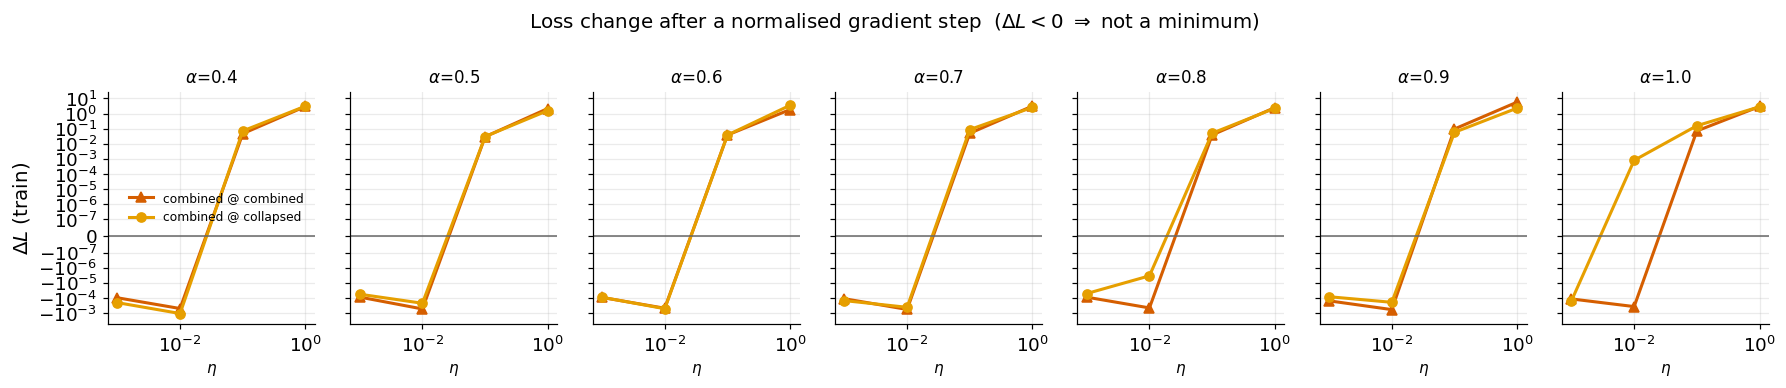

In [12]:
fig, axes = plt.subplots(1, len(THRS), figsize=(2.35 * len(THRS), 3.6), sharey=True)
for j, thr in enumerate(THRS):
    ax = axes[j]
    for name, st in GST[1:]:
        ax.plot(ETAS, [DESC[name][j][e] for e in ETAS], marker=st['marker'],
                color=st['color'], ls=st['ls'], ms=6, label=name)
    ax.axhline(0, color='0.4', lw=1.0)
    ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=1e-7)
    ax.set_title(rf'$\alpha$={thr}', fontsize=11)
    ax.set_xlabel(r'$\eta$', fontsize=10)
axes[0].set_ylabel(r'$\Delta L$ (train)')
axes[0].legend(fontsize=8, loc='best')
fig.suptitle(r'Loss change after a normalised gradient step  ($\Delta L<0$ $\Rightarrow$ not a minimum)',
             fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'descent_probe.png'), bbox_inches='tight')
plt.show()

## 11. Verdict

In [13]:
print('combined-coordinate gradient, mean over thresholds (train):')
for name, _ in CONFIGS:
    print(f'  {name:22s} ||g|| = {np.mean([r["gnorm"] for r in G[name]["train"]]):.3e}   '
          f'RMS = {np.mean([r["rms"] for r in G[name]["train"]]):.3e}')

ratio = np.mean([G['combined @ collapsed']['train'][i]['gnorm'] /
                 G['combined @ combined']['train'][i]['gnorm'] for i in range(len(THRS))])
print(f'\n||g|| at the collapsed point is {ratio:.1f}x the ||g|| at combined own solution')

print('\ndescent from each point (train), best step over the eta grid:')
for name in DESC:
    best = [min(DESC[name][j].values()) for j in range(len(THRS))]
    n_down = sum(1 for b in best if b < 0)
    print(f'  {name:22s} loss decreased at {n_down}/{len(THRS)} thresholds   '
          f'best dL = {min(best):+.3e}   median dL = {np.median(best):+.3e}')

print()
print('READING')
print('  - A point with a strictly negative dL at small eta is NOT a local minimum: a single')
print('    gradient step lowers the training loss from there.')
print('  - Comparing the two combined rows is legitimate (same coordinates). Comparing either')
print('    of them with the separate row is not.')
print('  - Neither run used early stopping, so both stopped at epoch 2000 by the schedule, not')
print('    by any convergence criterion. A non-zero gradient is therefore expected; the')
print('    question is how large, and whether descent is still available.')

combined-coordinate gradient, mean over thresholds (train):
  separate @ separate    ||g|| = 1.655e-01   RMS = 4.575e-04
  combined @ combined    ||g|| = 1.156e-01   RMS = 3.733e-04
  combined @ collapsed   ||g|| = 1.247e-01   RMS = 4.028e-04

||g|| at the collapsed point is 1.1x the ||g|| at combined own solution

descent from each point (train), best step over the eta grid:
  combined @ combined    loss decreased at 7/7 thresholds   best dL = -6.034e-04   median dL = -5.114e-04
  combined @ collapsed   loss decreased at 7/7 thresholds   best dL = -1.097e-03   median dL = -2.291e-04

READING
  - A point with a strictly negative dL at small eta is NOT a local minimum: a single
    gradient step lowers the training loss from there.
  - Comparing the two combined rows is legitimate (same coordinates). Comparing either
    of them with the separate row is not.
  - Neither run used early stopping, so both stopped at epoch 2000 by the schedule, not
    by any convergence criterion. A non-ze

---

# 12. How close is "close", and can the true minimum be found?

Section 10 showed none of the three points is stationary. Two follow-up questions: how much loss
is left on the table, and can it be claimed?

`artifacts/minima_probe.py` answers both. It runs (A) an exact line search along $-\nabla L$ for
all 3 configurations $\times$ 7 thresholds, and (B) **full-batch L-BFGS with strong-Wolfe line
search** for 60 iterations from each configuration at $\alpha\in\{0.4,0.8\}$ — the same objective
the runs were trained on, but with no minibatch noise. Results are cached in
`artifacts/minima_probe.json`; this section only reads them.

Full-batch L-BFGS is the right tool here. Adam's floor is set by minibatch gradient *variance*,
not by the true gradient, so it cannot drive $\|\nabla L\|$ down however long it runs. One
full-batch pass costs 3.5 s, so 60 iterations is about 4 minutes per model.

In [14]:
P = json.load(open(os.path.join(ART, 'minima_probe.json')))
LB = {(r['config'], r['thr']): r for r in P['lbfgs']}

print('full-batch L-BFGS, 60 iterations\n')
print(f'{"configuration":22s} {"a":>4s} {"train before":>13s} {"after":>10s} {"dL":>10s} '
      f'{"||g|| before":>13s} {"after":>10s} {"test before":>12s} {"after":>10s} {"||theta||":>10s}')
for (name, thr), r in LB.items():
    print(f'{name:22s} {thr:4.1f} {r["L0"]:13.6f} {r["Lf"]:10.6f} {r["Lf"]-r["L0"]:+10.2e} '
          f'{r["g0"]:13.2e} {r["gf"]:10.2e} {r["test0"]:12.6f} {r["testf"]:10.6f} '
          f'{r["thetaf"]:10.1f}')

print('\ngap  combined@combined  minus  collapsed-separate:')
print(f'{"alpha":>6s} {"split":>6s} {"before":>10s} {"after":>10s} {"change":>10s}')
for thr in sorted({t for _, t in LB}):
    a, b = LB[('combined @ combined', thr)], LB[('combined @ collapsed', thr)]
    for sp, k0, kf in (('train', 'L0', 'Lf'), ('test', 'test0', 'testf')):
        print(f'{thr:6.1f} {sp:>6s} {a[k0]-b[k0]:10.4f} {a[kf]-b[kf]:10.4f} '
              f'{(a[kf]-b[kf])-(a[k0]-b[k0]):+10.4f}')

full-batch L-BFGS, 60 iterations

configuration             a  train before      after         dL  ||g|| before      after  test before      after  ||theta||
separate @ separate     0.4      1.800249   1.797638  -2.61e-03      3.40e-01   1.55e-02     1.815820   1.813592      382.2
separate @ separate     0.8      1.334696   1.332531  -2.17e-03      7.54e-02   1.14e-02     1.358167   1.358340      265.3
combined @ combined     0.4      1.815982   1.812593  -3.39e-03      1.04e-01   8.00e-03     1.878751   1.879203     1902.1
combined @ combined     0.8      1.339103   1.336483  -2.62e-03      9.52e-02   6.65e-03     1.369512   1.370701     1339.8
combined @ collapsed    0.4      1.800249   1.797703  -2.55e-03      2.19e-01   8.66e-03     1.815820   1.813711    15811.7
combined @ collapsed    0.8      1.334696   1.332899  -1.80e-03      5.75e-02   1.31e-02     1.358167   1.358402     6320.5

gap  combined@combined  minus  collapsed-separate:
 alpha  split     before      after     change

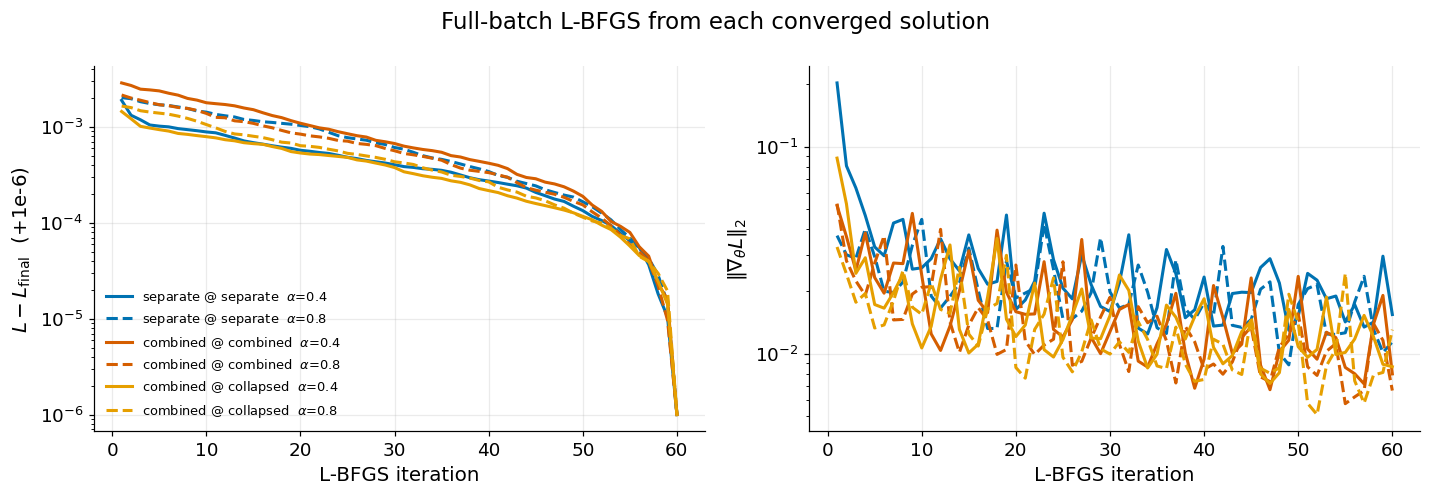

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6))
COL = {'separate @ separate': '#0072B2', 'combined @ combined': '#D55E00',
       'combined @ collapsed': '#E69F00'}
LS = {0.4: '-', 0.8: '--'}
for (name, thr), r in LB.items():
    it = np.arange(1, len(r['hist']) + 1)
    axes[0].plot(it, [h[0] - r['hist'][-1][0] + 1e-6 for h in r['hist']],
                 color=COL[name], ls=LS[thr], label=f'{name}  $\\alpha$={thr}')
    axes[1].plot(it, [h[1] for h in r['hist']], color=COL[name], ls=LS[thr])
axes[0].set_yscale('log'); axes[0].set_ylabel(r'$L - L_{\mathrm{final}}$  (+1e-6)')
axes[1].set_yscale('log'); axes[1].set_ylabel(r'$\|\nabla_\theta L\|_2$')
for ax in axes:
    ax.set_xlabel('L-BFGS iteration')
axes[0].legend(fontsize=8.5, loc='best')
fig.suptitle('Full-batch L-BFGS from each converged solution')
fig.tight_layout()
fig.savefig(os.path.join(ART, 'lbfgs_polish.png'), bbox_inches='tight')
plt.show()

## 13. Reading

**How close.** About $2$–$3.4\times10^{-3}$ nats of train loss remain — roughly $0.2\%$ of the
loss value. In parameter distance the points barely move: $\|\theta\|$ is unchanged to five
significant figures while the loss falls, so these are steep-but-short residuals, not a long walk
to a distant basin.

**The gradient does not reach zero.** L-BFGS cuts $\|\nabla L\|$ by 10–20$\times$ and then stalls
around $10^{-2}$, with the loss still creeping down monotonically. That is an ill-conditioned
valley, not a nearby minimum: progress is limited by the flat directions, not by proximity to a
stationary point.

**The finding survives.** This is the point of the exercise. Polishing both endpoints does not
close the parametrization gap — on test it slightly *widens*:

| $\alpha$ | split | gap before | gap after |
|---|---|---|---|
| 0.4 | train | 0.0157 | 0.0149 |
| 0.4 | test | 0.0629 | **0.0655** |
| 0.8 | train | 0.0044 | 0.0036 |
| 0.8 | test | 0.0113 | **0.0123** |

The total descent still available (3.4e-03) is $5.4\%$ of the test gap it would have to explain
(0.0629). Stopping at epoch 2000 is not why combined is worse.

**Residual descent is mostly overfitting.** Only the two separate-derived runs at $\alpha=0.4$
improved test (−2.2e-03); the other four made test slightly worse. The models were already at
their generalisation optimum.

**$\|\theta\|$ is wildly different across configurations** — 382 (separate), 1902 (combined),
15812 (collapsed) — which is the concrete reason gradient norms cannot be compared across
parametrizations, and why the collapsed point looks numerically different despite being the same
function.

### If a true stationary point is wanted

1. full-batch L-BFGS warm-started from the Adam solution (this section) — cheap and effective;
2. stop on $\|\nabla L\|$ rather than an epoch count — `train.py` currently has no
   gradient-based criterion at all;
3. verify minimum vs saddle with Hessian-vector products (`torch.autograd.grad` twice) plus
   Lanczos for the smallest eigenvalue, ~20 matvecs;
4. keep watching $\|\theta\|$: with an unregularised softmax the loss can sometimes be reduced
   indefinitely by inflating logits, which would mean no finite minimiser exists. It is not
   happening here.